# Sección 3 — Ratios de superficie y depuración previa al EDA

Trabajamos con las 48.487 propiedades que pasaron los controles de la parte 2. Transformamos las superficies internas en proporciones de `total_area` y pasamos `has_balcony` a 0/1 para estudiar las características de cada departamento sin repetir tres medidas de tamaño muy relacionadas.

Antes de ejecutar las celdas iniciamos el servidor local de MLflow indicado en `README.md`. Registramos cada uno de los siete modelos en un run separado del mismo experimento.

In [19]:
from pathlib import Path

import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn
import mlflow.statsmodels

mlflow.set_tracking_uri('http://127.0.0.1:5000')
mlflow.set_experiment('UTN_Mercado_Secundario')

RUTA_ENTRADA = Path('secondary_market_parte_2_con_antiguedad_y_floor_ratio.csv')
ventas_parte_2 = pd.read_csv(RUTA_ENTRADA)
columnas_requeridas = ['total_area', 'living_area', 'kitchen_area', 'floor', 'building_year', 'has_balcony', 'price_per_sqm']
faltantes_requeridas = set(columnas_requeridas) - set(ventas_parte_2.columns)
assert not faltantes_requeridas, f'Faltan columnas necesarias: {sorted(faltantes_requeridas)}'
assert (ventas_parte_2['total_area'] > 0).all(), 'total_area debe ser positivo para calcular los ratios'
assert ventas_parte_2['has_balcony'].dropna().isin([True, False]).all(), 'has_balcony debe contener booleanos'
assert not ventas_parte_2.isna().any().any(), 'El dataset de origen contiene nulos'
assert np.isfinite(ventas_parte_2.select_dtypes(include='number').to_numpy(dtype=float)).all(), 'El dataset de origen contiene infinitos'
print(f'Dataset de entrada: {len(ventas_parte_2):,} filas y {len(ventas_parte_2.columns)} columnas')

Dataset de entrada: 48,487 filas y 33 columnas


## 3.1. Proporciones y variables originales

Calculamos `living_ratio = living_area / total_area` y `kitchen_ratio = kitchen_area / total_area`. Después retiramos `living_area` y `kitchen_area`, porque en metros cuadrados dependían mucho del tamaño total. También conservamos `floor_ratio` y `antiguedad`, calculados en la parte 2, en lugar de `floor` y `building_year`.

In [20]:
ventas_parte_3 = ventas_parte_2.copy()
ventas_parte_3['living_ratio'] = ventas_parte_3['living_area'] / ventas_parte_3['total_area']
ventas_parte_3['kitchen_ratio'] = ventas_parte_3['kitchen_area'] / ventas_parte_3['total_area']
ventas_parte_3['has_balcony'] = ventas_parte_3['has_balcony'].astype(int)
columnas_a_descartar = [
    'id', 'date_posted', 'year_month', 'price_rub',
    'living_area', 'kitchen_area', 'floor', 'building_year', 'station_name',
]
columnas_presentes_descartar = [c for c in columnas_a_descartar if c in ventas_parte_3.columns]
columnas_ya_ausentes = [c for c in columnas_a_descartar if c not in ventas_parte_3.columns]
assert set(['living_area', 'kitchen_area', 'floor', 'building_year']).issubset(columnas_presentes_descartar)
ventas_parte_3 = ventas_parte_3.drop(columns=columnas_presentes_descartar)
assert len(ventas_parte_3) == len(ventas_parte_2)
assert ventas_parte_3['price_per_sqm'].equals(ventas_parte_2['price_per_sqm'])
assert ventas_parte_3['has_balcony'].isin([0, 1]).all()
assert not ventas_parte_3.isna().any().any(), 'El dataset resultante contiene nulos'
assert np.isfinite(ventas_parte_3.select_dtypes(include='number').to_numpy(dtype=float)).all(), 'El dataset resultante contiene infinitos'
print('Columnas eliminadas ahora:', columnas_presentes_descartar)
print('Columnas ya ausentes desde etapas previas:', columnas_ya_ausentes)
print(f'Dataset depurado para EDA: {len(ventas_parte_3):,} filas y {len(ventas_parte_3.columns)} columnas')
print(ventas_parte_3[['living_ratio', 'kitchen_ratio', 'has_balcony']].describe().to_string())

Columnas eliminadas ahora: ['living_area', 'kitchen_area', 'floor', 'building_year']
Columnas ya ausentes desde etapas previas: ['id', 'date_posted', 'year_month', 'price_rub', 'station_name']
Dataset depurado para EDA: 48,487 filas y 31 columnas
       living_ratio  kitchen_ratio   has_balcony
count  48487.000000   48487.000000  48487.000000
mean       0.624514       0.173165      0.749665
std        0.043262       0.047559      0.433210
min        0.548926       0.055659      0.000000
25%        0.586812       0.139208      0.000000
50%        0.624498       0.167038      1.000000
75%        0.661853       0.200870      1.000000
max        0.701128       0.419476      1.000000


## 3.2. Dataset depurado

Guardamos las 48.487 filas y 31 columnas con los ratios y el balcón codificado. Verificamos que no queden datos faltantes ni valores infinitos; las columnas `_join_distrito` y `_join_metro` quedan como registro de los cruces, pero no entrarán al OLS.

In [21]:
RUTA_SALIDA = Path('secondary_market_parte_3_limpio_eda.csv')
ventas_parte_3.to_csv(RUTA_SALIDA, index=False)
dataset_guardado = pd.read_csv(RUTA_SALIDA)
assert dataset_guardado.shape == ventas_parte_3.shape
assert dataset_guardado.columns.equals(ventas_parte_3.columns)
assert dataset_guardado['price_per_sqm'].equals(ventas_parte_2['price_per_sqm'])
assert not dataset_guardado.isna().any().any()
assert np.isfinite(dataset_guardado.select_dtypes(include='number').to_numpy(dtype=float)).all()
print(f'Dataset guardado en: {RUTA_SALIDA.resolve()}')
print(f'Filas: {len(dataset_guardado):,}; columnas: {len(dataset_guardado.columns)}')

Dataset guardado en: C:\Users\Rodrigo\Documents\Facultad\Analisis de datos\Parcial\2round\secondary_market_parte_3_limpio_eda.csv
Filas: 48,487; columnas: 31


# Sección 4 — EDA y multicolinealidad

Revisamos los estadísticos de las 12 variables numéricas que usaremos en la regresión. Incluimos `price_per_sqm` en los gráficos de correlación para ver su relación con las características del aviso y del barrio.

In [22]:
from matplotlib import pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

vars_numericas = [
    'total_area', 'living_ratio', 'kitchen_ratio', 'floor_ratio',
    'antiguedad', 'ceiling_height', 'has_balcony', 'metro_distance_min',
    'to_center_km', 'mortgage_rate_at_listing',
    'secondary_price_per_sqm', 'secondary_mom_change_pct',
]
eda = pd.read_csv(Path('secondary_market_parte_3_limpio_eda.csv'))
columnas_eda = vars_numericas + ['price_per_sqm']
assert set(columnas_eda + ['building_type', 'renovation']).issubset(eda.columns)
assert not eda[columnas_eda].isna().any().any()
assert np.isfinite(eda[columnas_eda].to_numpy(dtype=float)).all()
print(f'Observaciones: {len(eda):,}; variables numéricas explicativas: {len(vars_numericas)}')
display(eda[columnas_eda].describe().T)

Observaciones: 48,487; variables numéricas explicativas: 12


,count,mean,std,min,25%,50%,75%,max
total_area,48487.0,67.199121,17.227479,21.100000,54.600000,65.200000,77.600000,1.343000e+02
living_ratio,48487.0,0.624514,0.043262,0.548926,0.586812,0.624498,0.661853,7.011278e-01
kitchen_ratio,48487.0,0.173165,0.047559,0.055659,0.139208,0.167038,0.200870,4.194757e-01
floor_ratio,48487.0,0.545252,0.289117,0.040000,0.294118,0.555556,0.800000,1.000000e+00
antiguedad,48487.0,35.421742,23.209538,0.000000,14.000000,35.000000,55.000000,9.100000e+01
ceiling_height,48487.0,2.788469,0.221757,2.500000,2.700000,2.700000,3.000000,3.500000e+00
has_balcony,48487.0,0.749665,0.433210,0.000000,0.000000,1.000000,1.000000,1.000000e+00
metro_distance_min,48487.0,57.018294,54.465584,2.000000,22.000000,39.000000,71.000000,3.280000e+02
to_center_km,48487.0,16.317288,12.726358,0.070000,9.030000,13.230000,18.060000,7.055000e+01
mortgage_rate_at_listing,48487.0,14.592777,5.694159,6.750000,10.000000,12.000000,19.500000,2.350000e+01


## 4.1. Correlación de Pearson

El mapa de calor nos muestra asociaciones lineales entre las variables numéricas y el precio por metro cuadrado. Observamos una correlación alta entre `secondary_price_per_sqm` y el objetivo (0,888), además de una relación negativa entre el precio y la distancia al centro y al metro.

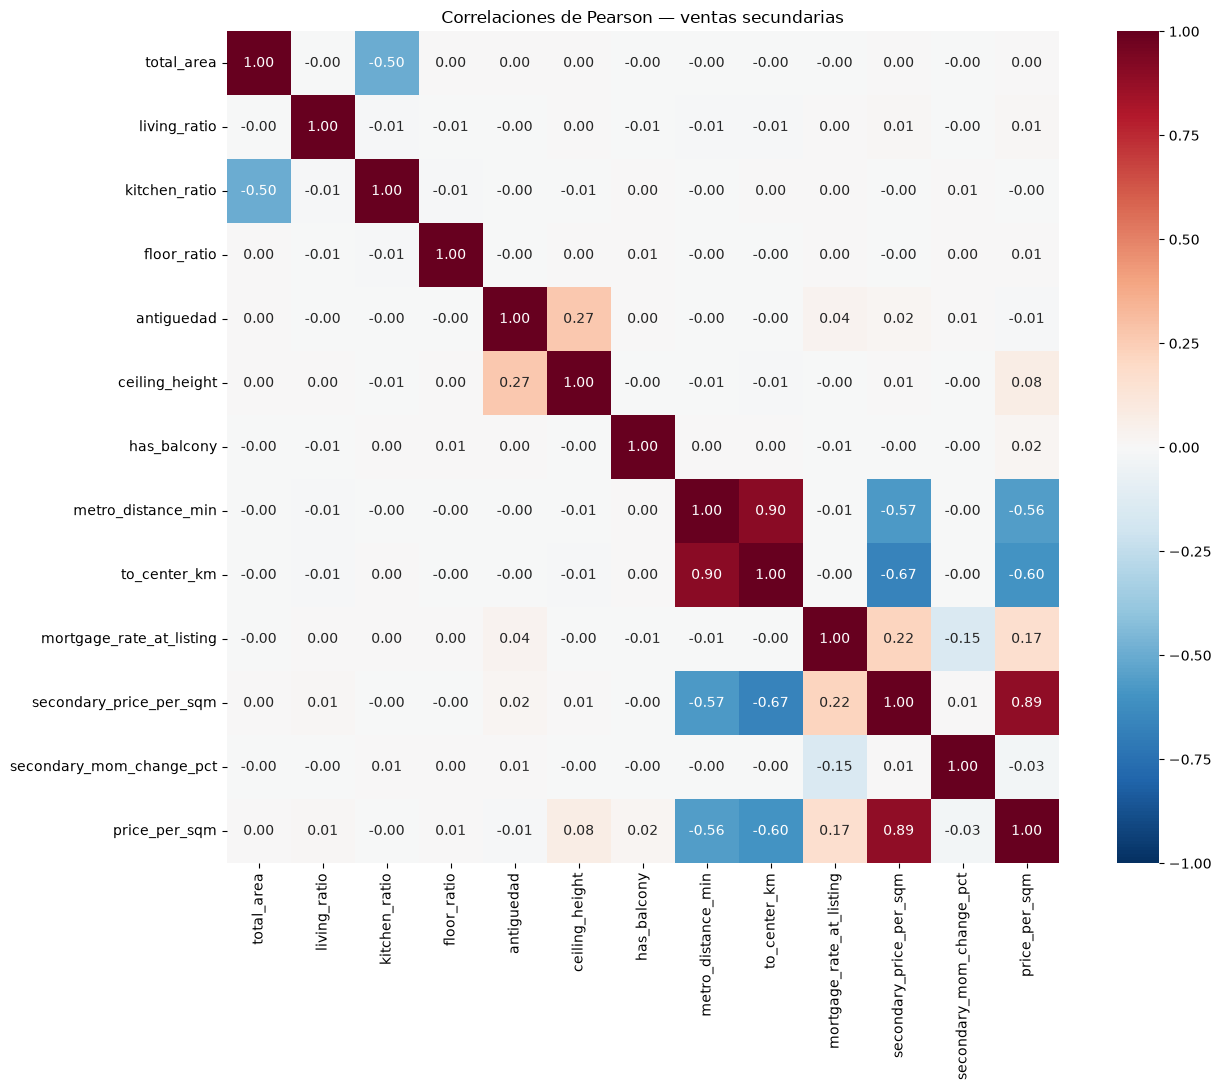

Correlación secondary_price_per_sqm vs price_per_sqm: 0.888


In [23]:
correlaciones_pearson = eda[columnas_eda].corr(method='pearson')
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(correlaciones_pearson, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0, square=True, ax=ax)
ax.set_title('Correlaciones de Pearson — ventas secundarias')
fig.tight_layout()
fig_correlaciones = fig
plt.show()
print('Correlación secondary_price_per_sqm vs price_per_sqm:', f"{correlaciones_pearson.loc['secondary_price_per_sqm', 'price_per_sqm']:.3f}")

## 4.2. Precio por tipo de edificio y renovación

Con los diagramas de caja comparamos `price_per_sqm` entre tipos de construcción y estados de renovación. Ocultamos los puntos extremos solo en el gráfico (`showfliers=False`) para ver mejor las cajas: no eliminamos esas observaciones.

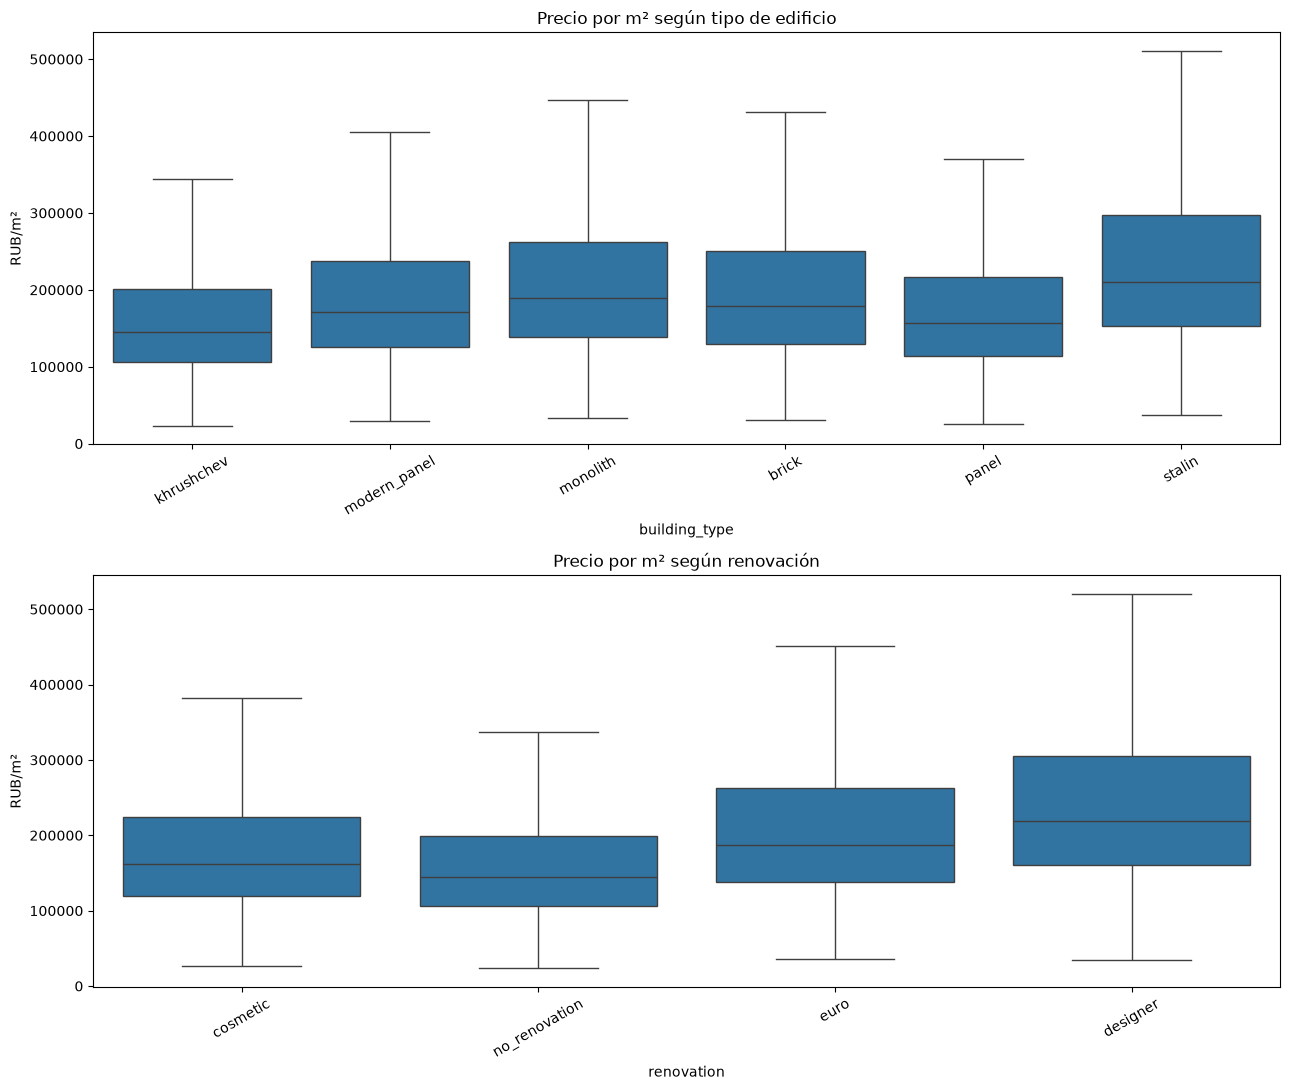

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(13, 11))
for ax, categoria, titulo in [
    (axes[0], 'building_type', 'Precio por m² según tipo de edificio'),
    (axes[1], 'renovation', 'Precio por m² según renovación'),
]:
    sns.boxplot(data=eda, x=categoria, y='price_per_sqm', showfliers=False, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel(categoria)
    ax.set_ylabel('RUB/m²')
    ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
fig_categorias = fig
plt.show()

## 4.3. Factor de Inflación de la Varianza (VIF)

Calculamos el VIF de las 12 variables numéricas con constante. Para medir el efecto de los ratios, repetimos el cálculo de `total_area` sobre las mismas filas, pero usando `living_area` y `kitchen_area` en lugar de sus proporciones.

In [25]:
X_vif = sm.add_constant(eda[vars_numericas].astype(float), has_constant='add')
matriz_vif = X_vif.to_numpy()
vif_numericas = pd.DataFrame([
    {'variable': nombre, 'vif': float(variance_inflation_factor(matriz_vif, posicion))}
    for posicion, nombre in enumerate(X_vif.columns) if nombre != 'const'
])
vif_numericas['tolerancia'] = 1 / vif_numericas['vif']
display(vif_numericas.sort_values('vif', ascending=False).reset_index(drop=True))

vars_areas_originales = [
    'living_area' if nombre == 'living_ratio' else
    'kitchen_area' if nombre == 'kitchen_ratio' else nombre
    for nombre in vars_numericas
]
ventas_antes_ratios = pd.read_csv(Path('secondary_market_parte_2_con_antiguedad_y_floor_ratio.csv'))
assert len(ventas_antes_ratios) == len(eda)
assert ventas_antes_ratios['price_per_sqm'].equals(eda['price_per_sqm'])
X_areas_originales = sm.add_constant(ventas_antes_ratios[vars_areas_originales].astype(float), has_constant='add')
posicion_total_area = X_areas_originales.columns.get_loc('total_area')
vif_total_area_original = float(variance_inflation_factor(X_areas_originales.to_numpy(), posicion_total_area))
vif_total_area_ratios = float(vif_numericas.set_index('variable').loc['total_area', 'vif'])
print(f'VIF total_area con superficies originales: {vif_total_area_original:.3f}')
print(f'VIF total_area con ratios: {vif_total_area_ratios:.3f}')
print('Todas las variables numéricas tienen VIF < 10:', bool((vif_numericas['vif'] < 10).all()))
assert len(vif_numericas) == len(vars_numericas)
assert np.isfinite(vif_numericas['vif']).all()

,variable,vif,tolerancia
0,to_center_km,6.700643,0.149239
1,metro_distance_min,5.399492,0.185203
2,secondary_price_per_sqm,2.013708,0.496596
3,kitchen_ratio,1.326342,0.753953
4,total_area,1.325822,0.754249
5,mortgage_rate_at_listing,1.129365,0.885453
6,antiguedad,1.082587,0.923714
7,ceiling_height,1.080754,0.925280
8,secondary_mom_change_pct,1.026464,0.974218
9,living_ratio,1.000506,0.999494


VIF total_area con superficies originales: 14.209
VIF total_area con ratios: 1.326
Todas las variables numéricas tienen VIF < 10: True


### Lectura del VIF

Al pasar las superficies internas a proporciones, el VIF de `total_area` baja de **14,21 a 1,33**. Todas las variables numéricas elegidas quedan por debajo de 10; las más relacionadas entre sí son `to_center_km` (6,70) y `metro_distance_min` (5,40). Este control se refiere a las numéricas seleccionadas, no a todas las dummies que añadiremos después.

## 4.4. Simetría del precio y zonas de la ciudad

Comparamos `price_per_sqm` con `log(price_per_sqm)` en las 48.487 ventas. Como vimos en clase, buscamos un `Skew` dentro de **[-0,5; 0,5]** y comparamos la curtosis de Pearson con **3**, el valor de una distribución normal o mesocúrtica. Para estudiar las zonas usamos CAO como referencia del centro y las propiedades renovadas (`euro` o `designer`) fuera de CAO como grupo de comparación; no son etiquetas comerciales oficiales de segmentos.

,escala,n,media,mediana,skew,kurtosis_pearson,skew_en_rango
0,RUB/m²,48487,196088.209211,170900.000000,1.689802,7.324486,False
1,log(RUB/m²),48487,12.034961,12.048834,-0.200833,3.221522,True


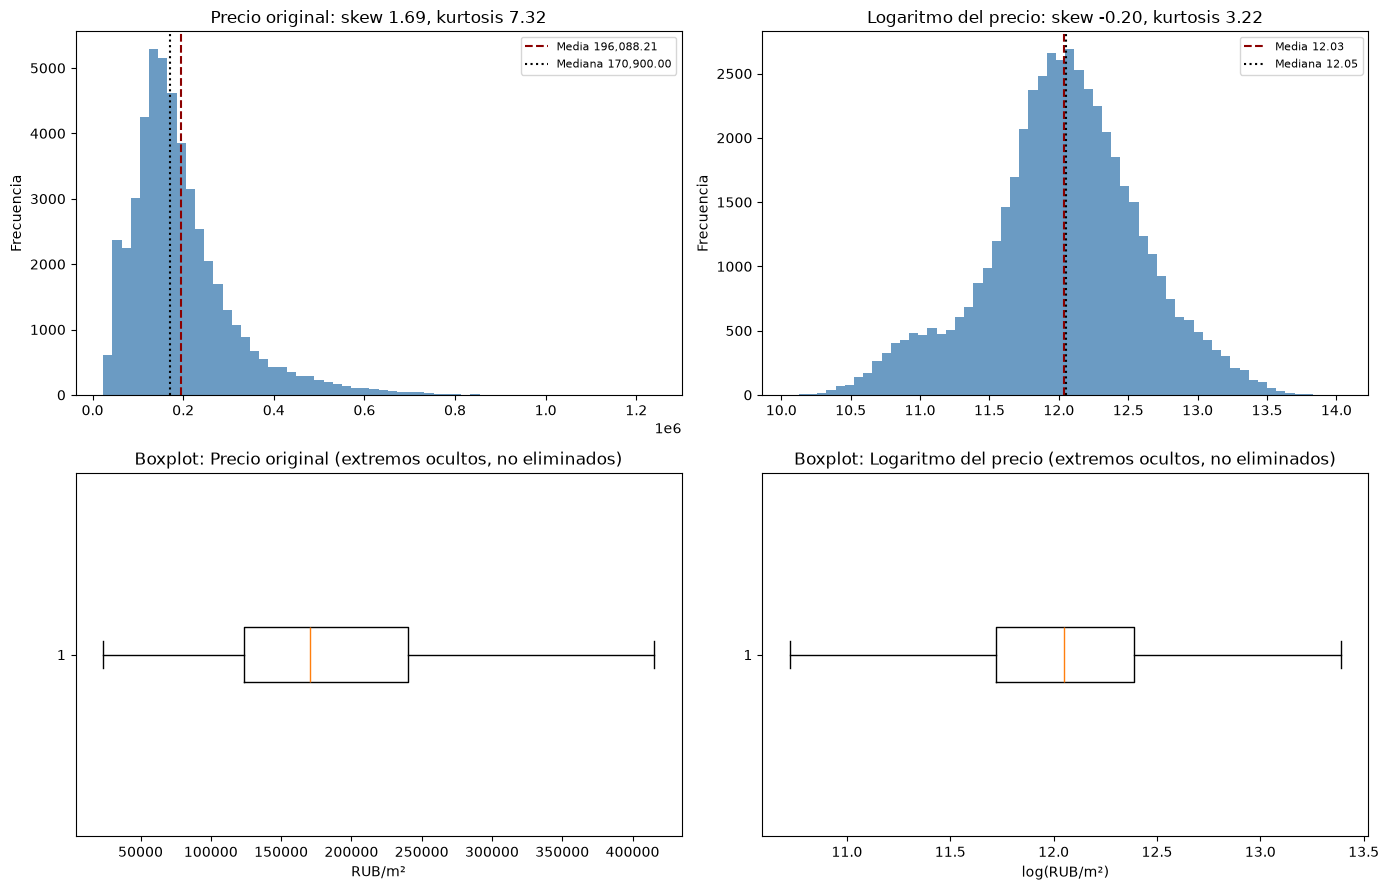

In [26]:
from scipy.stats import skew, kurtosis

precio_original = eda['price_per_sqm'].to_numpy(dtype=float)
precio_log = np.log(precio_original)
resumen_simetria = pd.DataFrame([
    {'escala': nombre, 'n': len(v), 'media': v.mean(), 'mediana': np.median(v),
     'skew': skew(v, bias=True), 'kurtosis_pearson': kurtosis(v, fisher=False, bias=True),
     'skew_en_rango': -0.5 <= skew(v, bias=True) <= 0.5}
    for nombre, v in [('RUB/m²', precio_original), ('log(RUB/m²)', precio_log)]
])
display(resumen_simetria)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for col, (nombre, v) in enumerate([('Precio original', precio_original), ('Logaritmo del precio', precio_log)]):
    ax = axes[0, col]
    ax.hist(v, bins=60, color='steelblue', alpha=.8)
    ax.axvline(v.mean(), color='darkred', ls='--', label=f'Media {v.mean():,.2f}')
    ax.axvline(np.median(v), color='black', ls=':', label=f'Mediana {np.median(v):,.2f}')
    ax.set(title=f'{nombre}: skew {skew(v):.2f}, kurtosis {kurtosis(v, fisher=False):.2f}', ylabel='Frecuencia')
    ax.legend(fontsize=8)
    axes[1, col].boxplot(v, orientation='horizontal', showfliers=False)
    axes[1, col].set(title=f'Boxplot: {nombre} (extremos ocultos, no eliminados)', xlabel='RUB/m²' if col == 0 else 'log(RUB/m²)')
fig.tight_layout()
fig_simetria = fig
plt.show()
assert abs(resumen_simetria.loc[0, 'skew'] - 1.69) < .02
assert abs(resumen_simetria.loc[1, 'skew'] + .20) < .02

### Solapamiento de precios y distancia al centro

Comparamos el decil de precios más altos fuera de CAO con la parte baja y media de CAO. También revisamos los rangos intercuartílicos y cómo cambia el precio mediano cuando aumenta `to_center_km`. Así podemos ver si existe una zona de precios compartida sin asumir que ambos grupos sean iguales.

,proxy,n,p10,p25,mediana,p75,p90
0,CAO,3763,294020.0,354000.0,437400.0,528150.0,627680.0
1,"Fuera de CAO, euro/designer",17808,89300.0,137500.0,186600.0,250100.0,320900.0


Intervalo compartido (decil alto fuera de CAO / p10-mediana CAO): 320,900–437,400 RUB/m²
Avisos fuera de CAO renovados en ese intervalo: 1,528
Intersección de IQR: 0 RUB/m²


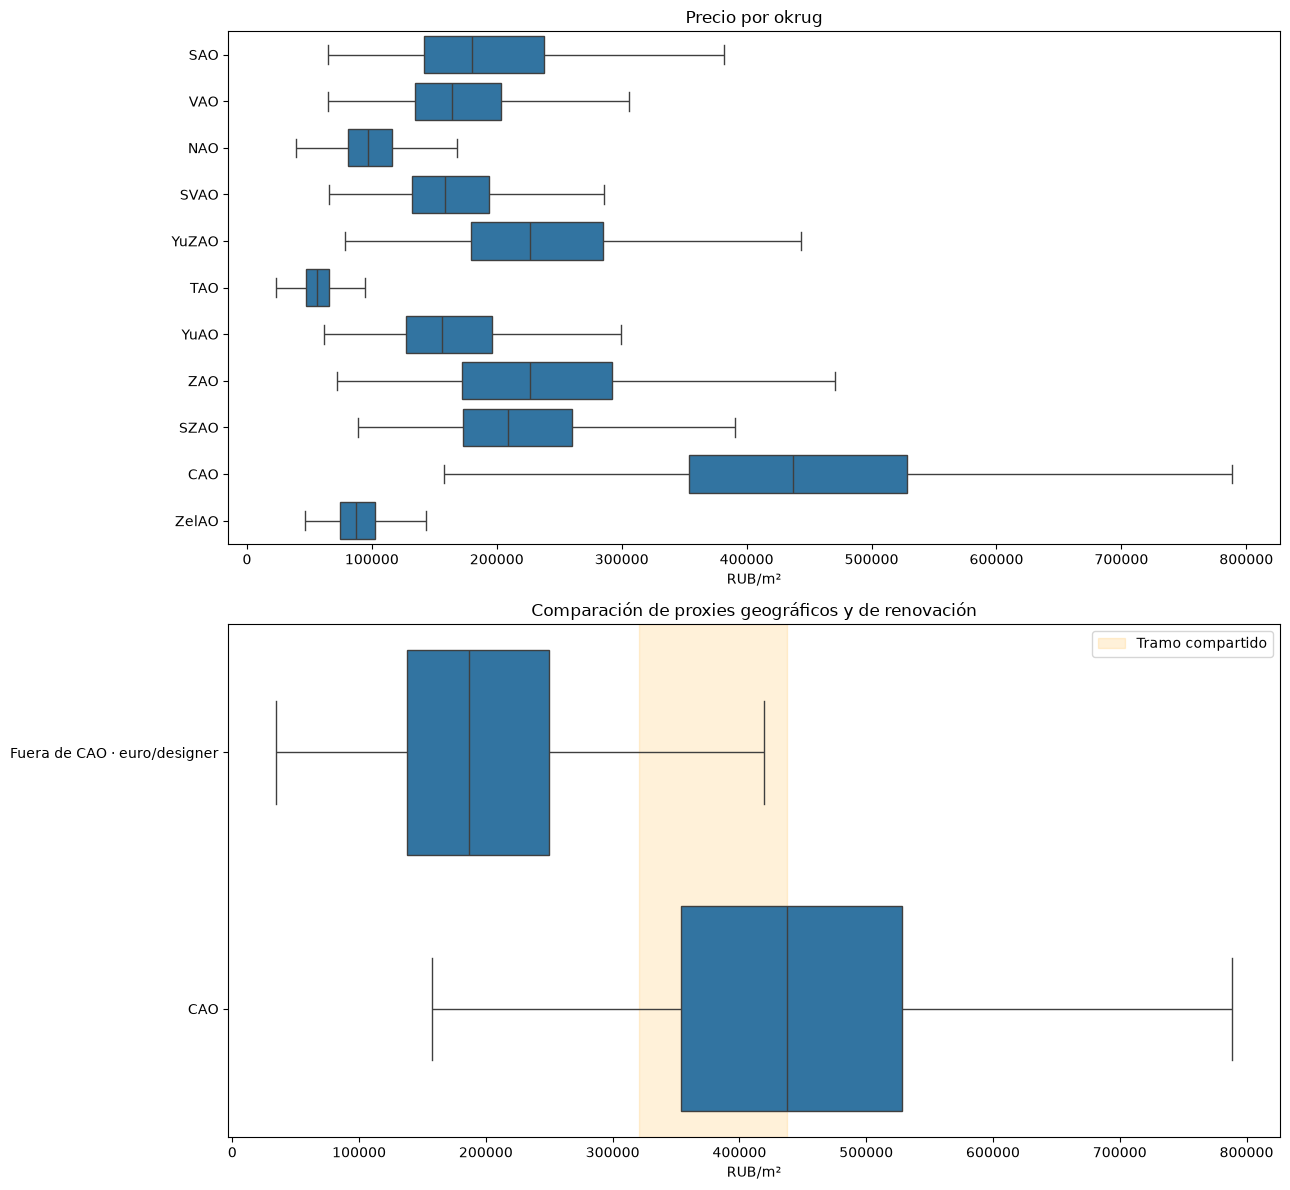

,quintil_distancia,n,distancia_mediana_km,precio_mediano_RUB_m2
0,"(0.069, 8.0]",9710,5.070,292500.0
1,"(8.0, 11.67]",9692,9.940,206900.0
2,"(11.67, 14.77]",9695,13.230,167700.0
3,"(14.77, 20.5]",9694,16.600,150400.0
4,"(20.5, 70.55]",9696,30.275,82600.0


In [9]:
cao = eda.loc[eda['okrug'].eq('CAO'), 'price_per_sqm']
otros = eda.loc[eda['okrug'].ne('CAO') & eda['renovation'].isin(['euro', 'designer']), 'price_per_sqm']
assert len(cao) > 0 and len(otros) > 0
segmentos = pd.DataFrame([
    {'proxy': nombre, 'n': len(v), 'p10': v.quantile(.1), 'p25': v.quantile(.25),
     'mediana': v.median(), 'p75': v.quantile(.75), 'p90': v.quantile(.9)}
    for nombre, v in [('CAO', cao), ('Fuera de CAO, euro/designer', otros)]
])
display(segmentos)
limite_inferior = max(otros.quantile(.9), cao.quantile(.1))
limite_superior = cao.median()
n_en_solapamiento = int(otros.between(limite_inferior, limite_superior).sum())
ancho_iqr_compartido = max(0, min(otros.quantile(.75), cao.quantile(.75)) - max(otros.quantile(.25), cao.quantile(.25)))
print(f'Intervalo compartido (decil alto fuera de CAO / p10-mediana CAO): {limite_inferior:,.0f}–{limite_superior:,.0f} RUB/m²')
print(f'Avisos fuera de CAO renovados en ese intervalo: {n_en_solapamiento:,}')
print(f'Intersección de IQR: {ancho_iqr_compartido:,.0f} RUB/m²')

comparables = eda.loc[eda['okrug'].eq('CAO') | (eda['okrug'].ne('CAO') & eda['renovation'].isin(['euro', 'designer']))].copy()
comparables['segmento_proxy'] = np.where(comparables['okrug'].eq('CAO'), 'CAO', 'Fuera de CAO · euro/designer')
fig, axes = plt.subplots(2, 1, figsize=(13, 12))
sns.boxplot(data=eda, x='price_per_sqm', y='okrug', showfliers=False, ax=axes[0])
axes[0].set(title='Precio por okrug', xlabel='RUB/m²', ylabel='')
sns.boxplot(data=comparables, x='price_per_sqm', y='segmento_proxy', showfliers=False, ax=axes[1])
axes[1].axvspan(limite_inferior, limite_superior, alpha=.15, color='orange', label='Tramo compartido')
axes[1].set(title='Comparación de proxies geográficos y de renovación', xlabel='RUB/m²', ylabel='')
axes[1].legend()
fig.tight_layout()
fig_zonas = fig
plt.show()
gradiente = eda[['to_center_km', 'price_per_sqm']].copy()
gradiente['quintil_distancia'] = pd.qcut(gradiente['to_center_km'], 5, duplicates='drop')
resumen_gradiente = gradiente.groupby('quintil_distancia', observed=True).agg(
    n=('price_per_sqm', 'size'), distancia_mediana_km=('to_center_km', 'median'),
    precio_mediano_RUB_m2=('price_per_sqm', 'median')).reset_index()
display(resumen_gradiente)
assert n_en_solapamiento > 0

El precio original tiene asimetría derecha (*Positive Skew* = **+1,69**) y curtosis de Pearson **7,32**. Con la transformación logarítmica, el `Skew` pasa a **−0,20**, dentro del rango de simetría de clase, y la curtosis se acerca a 3 (**3,22**). Entre **320.900 y 437.400 RUB/m²** encontramos **1.528 avisos** renovados fuera de CAO que comparten el tramo bajo/medio de precios de CAO. Los rangos intercuartílicos no se superponen: hablamos de un cruce en los extremos, no de dos distribuciones iguales. Por quintiles de distancia al centro, la mediana baja de **292.500** a **82.600 RUB/m²**. Por eso empezamos con un modelo log-lineal conjunto que incluye `to_center_km` y `okrug`; este gráfico no alcanza para descartar una segmentación en otro análisis.

# Sección 5 — Variables dummy y regresión OLS

Armamos tres regresiones sobre las mismas propiedades de entrenamiento y prueba: una con el precio original y dos con su logaritmo. Esto permite comparar la predicción en RUB/m² manteniendo fijo el conjunto de test.

## 5.1. Selección de variables y One-Hot Encoding

Usamos 12 variables numéricas y creamos variables dummy (`drop_first=True`) para cinco categóricas de pocas categorías: `building_type`, `renovation`, `okrug`, `metro_distance_type` y `seller_type`. Dejamos fuera `district` (129 barrios), `metro_station` (104 estaciones) y `metro_line` (12 líneas): sumarían **242 dummies** a las 20 actuales, es decir, **262 dummies y 274 predictores** en total, con posibles redundancias con `okrug`, `to_center_km` y `secondary_price_per_sqm`. Tampoco usamos las banderas de control de los cruces.

In [10]:
vars_numericas = [
    'total_area', 'living_ratio', 'kitchen_ratio', 'floor_ratio',
    'antiguedad', 'ceiling_height', 'has_balcony', 'metro_distance_min',
    'to_center_km', 'mortgage_rate_at_listing',
    'secondary_price_per_sqm', 'secondary_mom_change_pct',
]
vars_categoricas = [
    'building_type', 'renovation', 'okrug', 'metro_distance_type', 'seller_type',
]
eda = pd.read_csv(Path('secondary_market_parte_3_limpio_eda.csv'))
assert set(vars_numericas + vars_categoricas + ['price_per_sqm']).issubset(eda.columns)
X_codificado = pd.get_dummies(
    eda[vars_numericas + vars_categoricas],
    columns=vars_categoricas, drop_first=True, dtype=float,
)
dataset_ols = X_codificado.assign(price_per_sqm=eda['price_per_sqm'])
assert dataset_ols.columns[-1] == 'price_per_sqm'
assert not dataset_ols.isna().any().any(), 'Hay valores nulos'
assert np.isfinite(dataset_ols.to_numpy(dtype=float)).all(), 'Hay valores no finitos'
assert (dataset_ols['price_per_sqm'] > 0).all(), 'El logaritmo requiere objetivos positivos'
RUTA_OHE_OLS = Path('secondary_market_parte_4_ohe_ols.csv')
dataset_ols.to_csv(RUTA_OHE_OLS, index=False)
dataset_ols_guardado = pd.read_csv(RUTA_OHE_OLS)
assert dataset_ols_guardado.shape == dataset_ols.shape
assert dataset_ols_guardado.columns.equals(dataset_ols.columns)
assert not dataset_ols_guardado.isna().any().any()
assert np.isfinite(dataset_ols_guardado.to_numpy(dtype=float)).all()
print(f'Dataset codificado: {len(dataset_ols):,} filas; {X_codificado.shape[1]} predictores')
print(f'Guardado en: {RUTA_OHE_OLS.resolve()}')
print('Categorías de referencia (orden de pandas):')
for variable in vars_categoricas:
    print(f'  {variable}: {sorted(eda[variable].unique())[0]}')

Dataset codificado: 48,487 filas; 32 predictores
Guardado en: C:\Users\Rodrigo\Documents\Facultad\Analisis de datos\Parcial\2round\secondary_market_parte_4_ohe_ols.csv
Categorías de referencia (orden de pandas):
  building_type: brick
  renovation: cosmetic
  okrug: CAO
  metro_distance_type: transport
  seller_type: agency


## 5.2. Una división train/test para tres OLS

Dividimos las filas una sola vez (80/20, semilla 42): **38.789** para entrenar y **9.698** para probar. El Modelo 1 predice `price_per_sqm`; los Modelos 2 y 3 predicen su logaritmo. En el Modelo 3 quitamos las dos variables mensuales para ver cuánto podemos predecir solo con características del departamento y su ubicación si no contamos con el precio promedio del barrio de ese mes: aun así logra **R² = 0,8731** en test. Para evaluar los modelos logarítmicos en RUB/m² usamos el factor de Duan calculado solo con train. El R² de train del Modelo 1 está en otra escala que los R² de train de los modelos logarítmicos; las métricas de test sí están en la misma unidad.

En MLflow registramos el R² ajustado de train y las métricas de test en RUB/m². Para Ridge y Lasso calculamos el R² ajustado según la cantidad de coeficientes activos como medida descriptiva, no como prueba de significancia. Los modelos logarítmicos necesitan `exp` y el factor de Duan registrado para volver a RUB/m².

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = dataset_ols_guardado.drop(columns='price_per_sqm')
y = dataset_ols_guardado['price_per_sqm']
y_log = np.log(y)
X_train, X_test, y_train, y_test, y_train_log, y_test_log = train_test_split(
    X, y, y_log, test_size=0.20, random_state=42,
)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert X_train.index.equals(y_train_log.index) and X_test.index.equals(y_test_log.index)
X_train_const = sm.add_constant(X_train, has_constant='add')
X_test_const = sm.add_constant(X_test, has_constant='add')
indicadores_mensuales = ['secondary_price_per_sqm', 'secondary_mom_change_pct']
X_train_sin_mensuales = sm.add_constant(X_train.drop(columns=indicadores_mensuales), has_constant='add')
X_test_sin_mensuales = sm.add_constant(X_test.drop(columns=indicadores_mensuales), has_constant='add')
assert X_train_const.columns.equals(X_test_const.columns)
assert X_train_sin_mensuales.columns.equals(X_test_sin_mensuales.columns)

def registrar_modelo(tipo, escala, p, r2_adj, pred_test, modelo, duan=None,
                    alpha=None, cv=None, escalador=None):
    parametros = {'tipo_modelo': tipo.split()[0], 'escala_target': escala, 'p': int(p)}
    if tipo != parametros['tipo_modelo']:
        parametros['variante_modelo'] = tipo
    if alpha is not None:
        parametros['alpha'] = float(alpha)
    if cv is not None:
        parametros['cv_folds'] = cv
    mlflow.log_params(parametros)
    mlflow.log_param('cantidad_variables_predictoras', int(p))
    mlflow.log_param('predictores_entrada', X.shape[1])
    metricas = {
        'R2_Ajustado_Train': float(r2_adj),
        'R2_Test': float(r2_score(y_test, pred_test)),
        'MAE_Test': float(mean_absolute_error(y_test, pred_test)),
        'RMSE_Test': float(np.sqrt(mean_squared_error(y_test, pred_test))),
    }
    if duan is not None:
        metricas['Factor_Duan_Train'] = float(duan)
    mlflow.log_metrics(metricas)
    r2_train = (float(modelo.rsquared) if escalador is None
                else float(r2_score(y_train_log, modelo.predict(X_train_scaled))))
    mlflow.log_metric('R2_Train', r2_train)
    mlflow.log_metric('test_r2', metricas['R2_Test'])
    mlflow.log_metric('test_mae_RUB_m2', metricas['MAE_Test'])
    mlflow.log_metric('test_rmse_RUB_m2', metricas['RMSE_Test'])
    if duan is not None:
        mlflow.log_metric('duan_factor', float(duan))
    if escalador is None:
        mlflow.statsmodels.log_model(modelo, name='modelo')
    else:
        from sklearn.pipeline import Pipeline
        mlflow.sklearn.log_model(
            Pipeline([('escalador', escalador), ('regresion', modelo)]),
            name='modelo', skops_trusted_types=['sklearn.model_selection._split.KFold'],
        )


def r2_ajustado_regularizado(pred_train, p):
    n = len(y_train_log)
    return 1 - (1 - r2_score(y_train_log, pred_train)) * (n - 1) / (n - p - 1)

with mlflow.start_run(run_name='OLS_Lineal') as run_ols_lineal:
    modelo_1_lineal = sm.OLS(y_train, X_train_const).fit()
    pred_test_1 = modelo_1_lineal.predict(X_test_const)
    registrar_modelo('OLS', 'RUB/m2', X_train.shape[1], modelo_1_lineal.rsquared_adj,
                    pred_test_1, modelo_1_lineal)

with mlflow.start_run(run_name='OLS_Log_Completo') as run_ols_log:
    modelo_2_log = sm.OLS(y_train_log, X_train_const).fit()
    duan_modelo_2 = float(np.exp(modelo_2_log.resid).mean())
    pred_test_2 = np.exp(modelo_2_log.predict(X_test_const)) * duan_modelo_2
    registrar_modelo('OLS', 'log(RUB/m2)', X_train.shape[1], modelo_2_log.rsquared_adj,
                    pred_test_2, modelo_2_log, duan=duan_modelo_2)

with mlflow.start_run(run_name='OLS_Log_Sin_Mensuales') as run_ols_sin_mensuales:
    modelo_3_log_sin_mensuales = sm.OLS(y_train_log, X_train_sin_mensuales).fit()
    duan_modelo_3 = float(np.exp(modelo_3_log_sin_mensuales.resid).mean())
    pred_test_3 = np.exp(modelo_3_log_sin_mensuales.predict(X_test_sin_mensuales)) * duan_modelo_3
    registrar_modelo('OLS', 'log(RUB/m2)', X_train_sin_mensuales.shape[1] - 1,
                    modelo_3_log_sin_mensuales.rsquared_adj, pred_test_3,
                    modelo_3_log_sin_mensuales, duan=duan_modelo_3)
assert all(np.isfinite(p).all() for p in [pred_test_1, pred_test_2, pred_test_3])

comparacion_ols = pd.DataFrame([
    {
        'modelo': nombre, 'escala_R2_train': escala,
        'r2_train': float(modelo.rsquared),
        'r2_ajustado_train': float(modelo.rsquared_adj),
        'r2_test_RUB_m2': float(r2_score(y_test, pred)),
        'mae_test_RUB_m2': float(mean_absolute_error(y_test, pred)),
        'rmse_test_RUB_m2': float(np.sqrt(mean_squared_error(y_test, pred))),
        'factor_duan_train': factor,
    }
    for nombre, escala, modelo, pred, factor in [
        ('1. OLS lineal', 'RUB/m²', modelo_1_lineal, pred_test_1, np.nan),
        ('2. OLS log-lineal', 'log(RUB/m²)', modelo_2_log, pred_test_2, duan_modelo_2),
        ('3. OLS log sin mensuales', 'log(RUB/m²)', modelo_3_log_sin_mensuales, pred_test_3, duan_modelo_3),
    ]
])
print(f'Train: {len(X_train):,}; Test: {len(X_test):,}; mismos índices para los tres modelos')
display(comparacion_ols)

🏃 View run OLS_Lineal at: http://127.0.0.1:5000/#/experiments/5/runs/cf13f1eaac2247c8b1772a51959afd11
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5
🏃 View run OLS_Log_Completo at: http://127.0.0.1:5000/#/experiments/5/runs/e6cd3d27321349549f17a9b08c094141
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5
🏃 View run OLS_Log_Sin_Mensuales at: http://127.0.0.1:5000/#/experiments/5/runs/9a418b75fe564f53b9b9cee5c7031194
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5
Train: 38,789; Test: 9,698; mismos índices para los tres modelos


,modelo,escala_R2_train,r2_train,r2_ajustado_train,r2_test_RUB_m2,mae_test_RUB_m2,rmse_test_RUB_m2,factor_duan_train
0,1. OLS lineal,RUB/m²,0.913396,0.913324,0.913225,23224.612975,33601.673921,NaN
1,2. OLS log-lineal,log(RUB/m²),0.948552,0.948510,0.914842,20493.906012,33287.148716,1.008006
2,3. OLS log sin mensuales,log(RUB/m²),0.902176,0.902100,0.873093,27658.675172,40635.701565,1.015356


### Comparación de superficies originales y ratios

Probamos dos OLS logarítmicos con las mismas filas, el mismo split 80/20 y las mismas variables salvo las superficies: uno usa `living_area` y `kitchen_area`, y el otro usa `living_ratio` y `kitchen_ratio`. Registramos ambos en MLflow para comparar VIF y error de test en RUB/m². Una reducción del VIF no garantiza por sí sola una mejora en la predicción.

In [ ]:
# Las columnas originales provienen de las mismas filas usadas para calcular los ratios.
assert len(ventas_antes_ratios) == len(X)
assert ventas_antes_ratios['price_per_sqm'].equals(y)
X_areas_originales = X.rename(columns={
    'living_ratio': 'living_area', 'kitchen_ratio': 'kitchen_area',
}).copy()
X_areas_originales[['living_area', 'kitchen_area']] = ventas_antes_ratios[
    ['living_area', 'kitchen_area']
].to_numpy()
assert X_areas_originales.index.equals(X.index)
assert X_areas_originales.shape == X.shape
X_train_areas = sm.add_constant(X_areas_originales.loc[X_train.index], has_constant='add')
X_test_areas = sm.add_constant(X_areas_originales.loc[X_test.index], has_constant='add')
assert X_train_areas.index.equals(y_train_log.index)
assert X_test_areas.index.equals(y_test.index)

comparacion_superficies = []
runs_superficies = {}
for nombre, conjunto, matriz_train, matriz_test, vif_total_area in [
    ('OLS_Log_Areas_Originales', 'areas_originales', X_train_areas, X_test_areas, vif_total_area_original),
    ('OLS_Log_Ratios', 'ratios', X_train_const, X_test_const, vif_total_area_ratios),
]:
    with mlflow.start_run(run_name=nombre) as run_superficies:
        runs_superficies[conjunto] = run_superficies.info.run_id
        mlflow.set_tags({
            'comparison_group': 'superficies_originales_vs_ratios',
            'feature_set': conjunto,
            'split_id': 'random_80_20_seed_42',
        })
        modelo_superficies = sm.OLS(y_train_log, matriz_train).fit()
        duan_superficies = float(np.exp(modelo_superficies.resid).mean())
        pred_superficies = np.exp(modelo_superficies.predict(matriz_test)) * duan_superficies
        registrar_modelo('OLS', 'log(RUB/m2)', matriz_train.shape[1] - 1,
                        modelo_superficies.rsquared_adj, pred_superficies,
                        modelo_superficies, duan=duan_superficies)
        mlflow.log_param('conjunto_superficies', conjunto)
        mlflow.log_metric('vif_total_area', float(vif_total_area))
        comparacion_superficies.append({
            'variables_superficie': conjunto,
            'p': matriz_train.shape[1] - 1,
            'vif_total_area': float(vif_total_area),
            'r2_test_RUB_m2': float(r2_score(y_test, pred_superficies)),
            'mae_test_RUB_m2': float(mean_absolute_error(y_test, pred_superficies)),
            'rmse_test_RUB_m2': float(np.sqrt(mean_squared_error(y_test, pred_superficies))),
        })

comparacion_superficies = pd.DataFrame(comparacion_superficies)
display(comparacion_superficies)


## 5.3. Coeficientes del OLS log-lineal

La tabla presenta los coeficientes del Modelo 2 y su efecto porcentual para un cambio de una unidad, calculado como `(exp(beta) - 1) × 100`. Para una dummy lo comparamos con la categoría de referencia. También mostramos los errores estándar, el estadístico t y los p-values del OLS usado en clase; no eliminamos variables solo por mirar una tabla.

In [12]:
inferencia_modelo_2 = pd.DataFrame({
    'variable': modelo_2_log.params.index,
    'coeficiente_beta': modelo_2_log.params.to_numpy(),
    'impacto_porcentual': np.expm1(modelo_2_log.params.to_numpy()) * 100,
    'std_err': modelo_2_log.bse.to_numpy(),
    't_stat': modelo_2_log.tvalues.to_numpy(),
    'p_value': modelo_2_log.pvalues.to_numpy(),
})
inferencia_modelo_2['significativa_al_5pct'] = inferencia_modelo_2['p_value'] < 0.05
inferencia_modelo_2 = inferencia_modelo_2.sort_values('p_value').reset_index(drop=True)
display(inferencia_modelo_2)
no_significativas = inferencia_modelo_2.loc[
    ~inferencia_modelo_2['significativa_al_5pct'] & (inferencia_modelo_2['variable'] != 'const'), 'variable'
].tolist()
print('Variables no significativas al 5 % (sin contar constante):', no_significativas or 'ninguna')

,variable,coeficiente_beta,impacto_porcentual,std_err,t_stat,p_value,significativa_al_5pct
0,const,11.076054,6.460446e+06,1.685287e-02,657.220737,0.000000e+00,True
1,building_type_khrushchev,-0.211929,-1.909782e+01,2.429203e-03,-87.242372,0.000000e+00,True
2,secondary_price_per_sqm,0.000003,2.772552e-04,1.483416e-08,186.903006,0.000000e+00,True
3,metro_distance_min,-0.001830,-1.828722e-01,3.202145e-05,-57.161554,0.000000e+00,True
4,renovation_no_renovation,-0.111539,-1.055438e+01,1.759631e-03,-63.387943,0.000000e+00,True
5,renovation_euro,0.146575,1.578616e+01,1.553096e-03,94.375903,0.000000e+00,True
6,renovation_designer,0.310223,3.637296e+01,2.281645e-03,135.964744,0.000000e+00,True
7,building_type_panel,-0.130572,-1.224069e+01,2.065865e-03,-63.204638,0.000000e+00,True
8,metro_distance_type_walk,0.170301,1.856612e+01,1.880542e-03,90.559315,0.000000e+00,True
9,to_center_km,-0.005917,-5.899891e-01,1.811746e-04,-32.661117,7.629735e-231,True


Variables no significativas al 5 % (sin contar constante): ['living_ratio', 'okrug_TAO', 'seller_type_owner', 'kitchen_ratio', 'total_area']


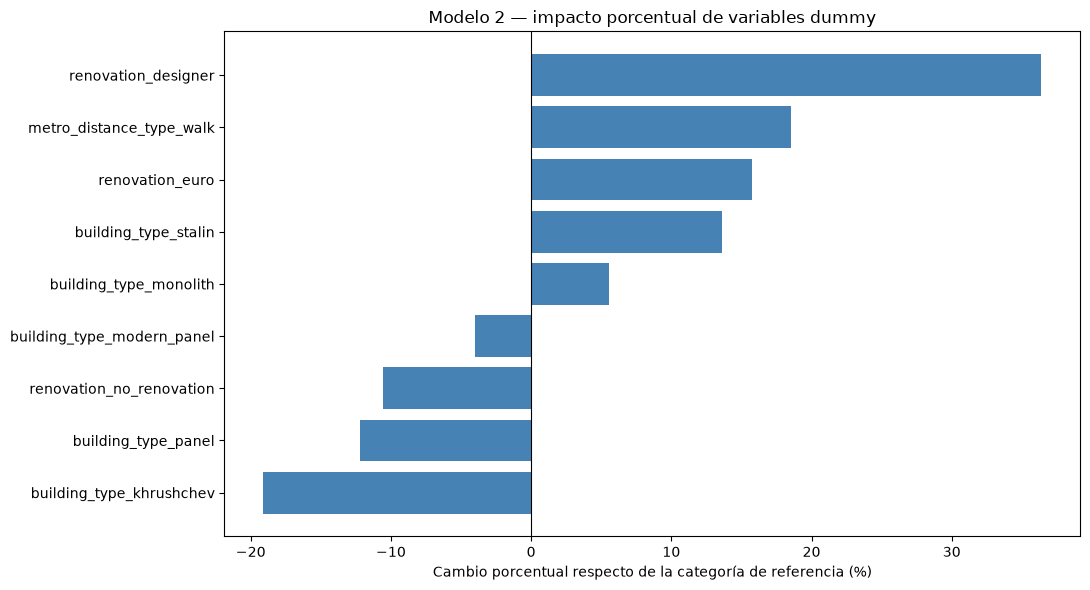

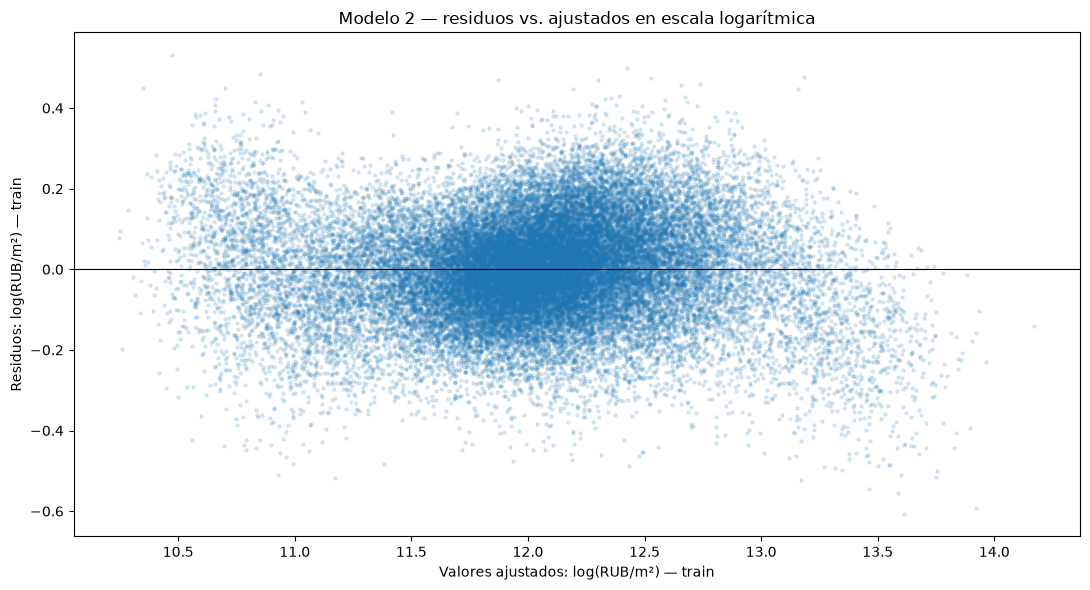

In [13]:
nombres_dummies_grafico = [
    nombre for nombre in inferencia_modelo_2['variable']
    if nombre.startswith(('building_type_', 'renovation_'))
    or nombre == 'metro_distance_type_walk'
]
impactos_dummies = (inferencia_modelo_2.set_index('variable')
    .loc[nombres_dummies_grafico, 'impacto_porcentual'].sort_values())
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(impactos_dummies.index, impactos_dummies.values, color='steelblue')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Cambio porcentual respecto de la categoría de referencia (%)')
ax.set_title('Modelo 2 — impacto porcentual de variables dummy')
fig.tight_layout()
fig_impactos_dummy = fig
plt.show()

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(modelo_2_log.fittedvalues, modelo_2_log.resid, s=5, alpha=0.14)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Valores ajustados: log(RUB/m²) — train')
ax.set_ylabel('Residuos: log(RUB/m²) — train')
ax.set_title('Modelo 2 — residuos vs. ajustados en escala logarítmica')
fig.tight_layout()
fig_residuos_ols = fig
plt.show()

### Resultados de los tres OLS

En el mismo test y en RUB/m², el Modelo 1 obtuvo **R² = 0,9132**, **MAE = 23.224,61** y **RMSE = 33.601,67**. El Modelo 2 log-lineal mejoró a **R² = 0,9148**, **MAE = 20.493,91** y **RMSE = 33.287,15**. El Modelo 3, sin las variables mensuales, mantuvo **R² = 0,8731**, con **MAE = 27.658,68** y **RMSE = 40.635,70**.

En el Modelo 2 encontramos cinco variables con `p >= 0,05`: `living_ratio`, `okrug_TAO`, `seller_type_owner`, `kitchen_ratio` y `total_area`. Revisamos su eliminación paso a paso en la sección siguiente, ya que los p-values cambian al volver a ajustar el modelo.

# Sección 6 — Residuos, selección de variables y regularización

Seguimos con las mismas **38.789** filas de train y **9.698** de test. Primero revisamos los residuos del Modelo 2; después buscamos una versión OLS más simple con *Backward Stepwise* y comparamos Ridge y Lasso con validación cruzada. Para las métricas de test de los modelos logarítmicos volvemos a RUB/m² usando el factor de Duan calculado en train.

## 6.1. Diagnóstico de residuos

Revisamos la media de residuos, Durbin–Watson, `Skew`, curtosis de Pearson y las pruebas Omnibus y Jarque–Bera. La figura reúne los cuatro gráficos trabajados en teoría: histograma, QQ-Plot, residuos frente a valores ajustados y Scale-Location, que nos ayuda a mirar si cambia la dispersión de los errores. Durbin–Watson debe leerse con cuidado: como dividimos las filas al azar, un valor cercano a 2 no demuestra independencia de errores a lo largo del tiempo.

,valor
modelo,2. OLS log-lineal
media_residuos_log,0.0
durbin_watson,1.995221
DW_en_rango_1_5_a_2_5,True
skew,-0.120005
skew_en_rango_menos_0_5_a_0_5,True
kurtosis_pearson,3.345211
omnibus_stat,234.007961
omnibus_p_value,0.0
jarque_bera_stat,285.476207


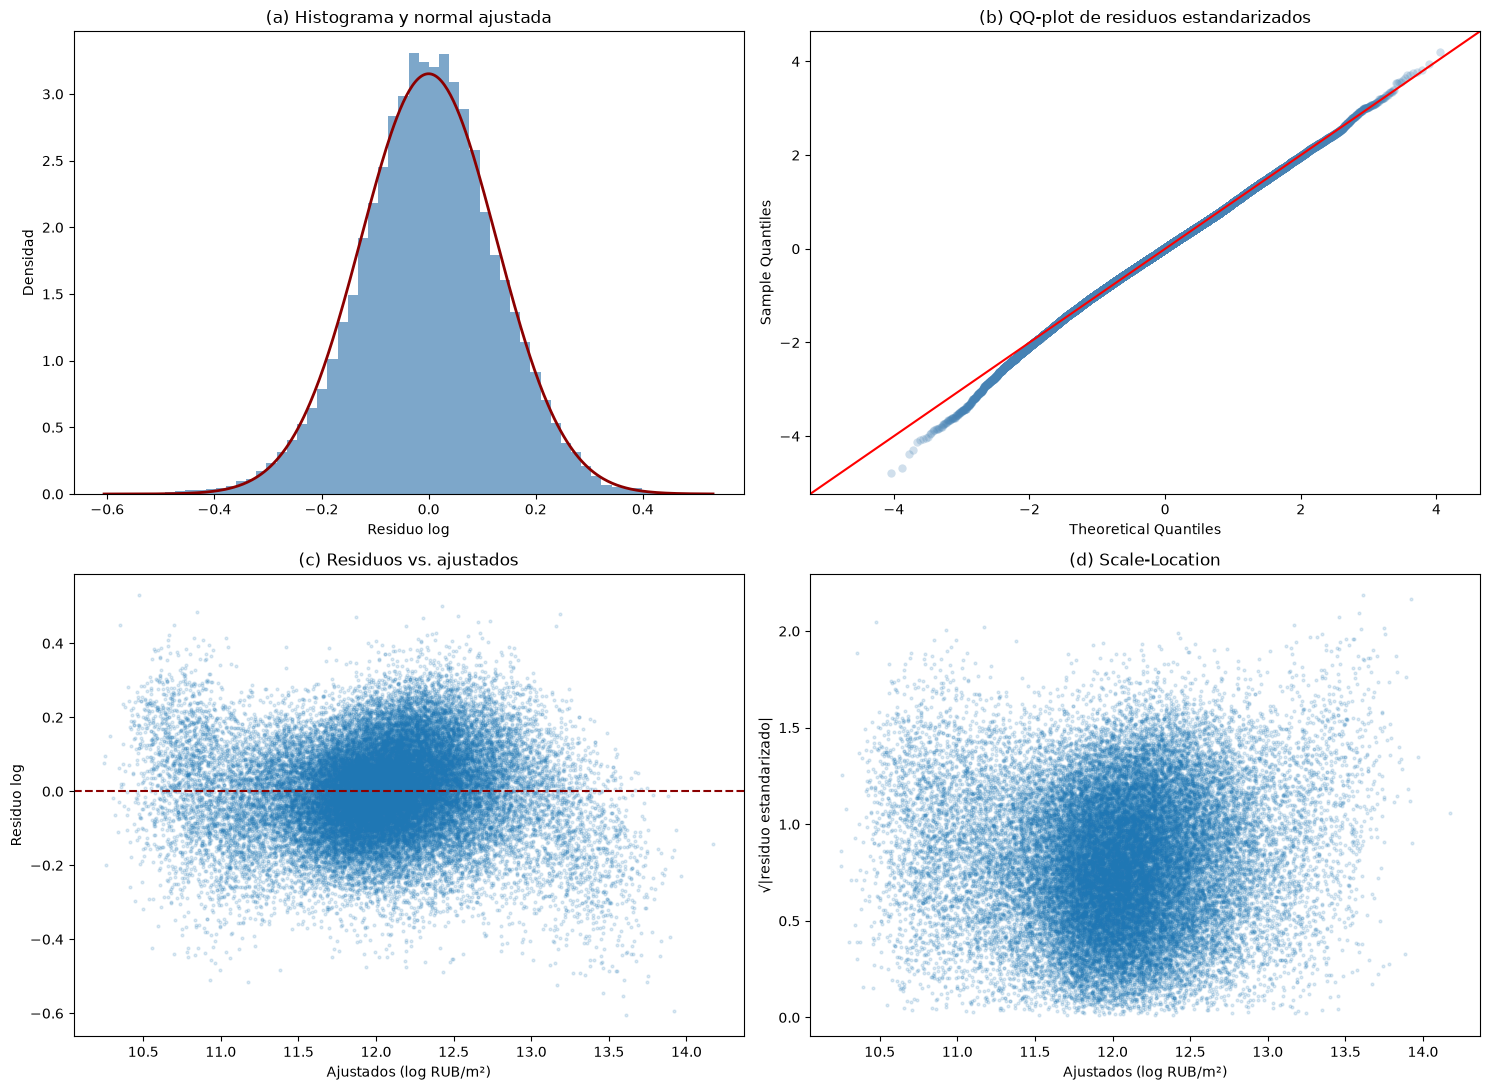

In [14]:
from scipy.stats import skew, kurtosis, norm
from statsmodels.stats.stattools import durbin_watson, jarque_bera, omni_normtest

residuos_log_2 = modelo_2_log.resid.to_numpy()
estadistico_omnibus, p_omnibus = omni_normtest(residuos_log_2)
estadistico_jb, p_jb, _, _ = jarque_bera(residuos_log_2)
dw_modelo_2 = float(durbin_watson(residuos_log_2))
skew_modelo_2 = float(skew(residuos_log_2, bias=False))
diagnostico_residuos_2 = pd.DataFrame([{
    'modelo': '2. OLS log-lineal',
    'media_residuos_log': float(residuos_log_2.mean()),
    'durbin_watson': dw_modelo_2,
    'DW_en_rango_1_5_a_2_5': bool(1.5 <= dw_modelo_2 <= 2.5),
    'skew': skew_modelo_2,
    'skew_en_rango_menos_0_5_a_0_5': bool(-0.5 <= skew_modelo_2 <= 0.5),
    'kurtosis_pearson': float(kurtosis(residuos_log_2, fisher=False, bias=False)),
    'omnibus_stat': float(estadistico_omnibus),
    'omnibus_p_value': float(p_omnibus),
    'jarque_bera_stat': float(estadistico_jb),
    'jarque_bera_p_value': float(p_jb),
    'aic': float(modelo_2_log.aic),
    'bic': float(modelo_2_log.bic),
}])
display(diagnostico_residuos_2.T.rename(columns={0: 'valor'}))

sigma_residuo_log = np.sqrt(modelo_2_log.mse_resid)
residuos_estandarizados_log = residuos_log_2 / sigma_residuo_log
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
ax = axes[0, 0]
ax.hist(residuos_log_2, bins=60, density=True, color='steelblue', alpha=0.7)
valores_curva = np.linspace(residuos_log_2.min(), residuos_log_2.max(), 400)
ax.plot(valores_curva, norm.pdf(valores_curva, residuos_log_2.mean(), residuos_log_2.std(ddof=1)), color='darkred', lw=2)
ax.set(title='(a) Histograma y normal ajustada', xlabel='Residuo log', ylabel='Densidad')
sm.qqplot(residuos_estandarizados_log, line='45', ax=axes[0, 1], markerfacecolor='steelblue', markeredgecolor='none', alpha=0.25)
axes[0, 1].set_title('(b) QQ-plot de residuos estandarizados')
axes[1, 0].scatter(modelo_2_log.fittedvalues, residuos_log_2, s=4, alpha=0.15)
axes[1, 0].axhline(0, color='darkred', linestyle='--')
axes[1, 0].set(title='(c) Residuos vs. ajustados', xlabel='Ajustados (log RUB/m²)', ylabel='Residuo log')
axes[1, 1].scatter(modelo_2_log.fittedvalues, np.sqrt(np.abs(residuos_estandarizados_log)), s=4, alpha=0.15)
axes[1, 1].set(title='(d) Scale-Location', xlabel='Ajustados (log RUB/m²)', ylabel='√|residuo estandarizado|')
fig.tight_layout()
fig_diagnostico_residuos = fig
plt.show()

## 6.2. Backward Stepwise

Empezamos con 32 predictores y retiramos en cada paso el de mayor p-value cuando es `>= 0,05`. Ajustamos de nuevo el OLS y registramos RSS, R² ajustado, AIC y BIC. Así podemos ver qué cambia al sacar variables en vez de eliminar las cinco al mismo tiempo.

Además del run final, guardamos en MLflow cada ajuste intermedio con la variable retirada, cantidad de predictores, AIC, BIC y métricas sobre el mismo test. La decisión de retirar variables sigue dependiendo de los p-values de train; no elegimos el paso mirando el test.

,paso,variable_retirada,p_value_retirado,predictores_activos,rss_log,r2_ajustado_log,aic,bic,delta_aic,delta_bic
0,0,ninguna (modelo completo),NaN,32,621.468224,0.948510,-50201.833923,-49919.159488,NaN,NaN
1,1,total_area,0.809350,31,621.469157,0.948511,-50203.775664,-49929.667121,-1.941741,-10.507633
2,2,kitchen_ratio,0.618977,30,621.473123,0.948512,-50205.528149,-49939.985497,-1.752485,-10.318377
3,3,seller_type_owner,0.495153,29,621.480584,0.948512,-50207.062462,-49950.085702,-1.534313,-10.100205
4,4,okrug_TAO,0.197469,28,621.507218,0.948512,-50207.400157,-49958.989289,-0.337695,-8.903587
5,5,living_ratio,0.069100,27,621.560204,0.948509,-50206.093366,-49966.248391,1.306791,-7.259101


Variables retiradas: ['total_area', 'kitchen_ratio', 'seller_type_owner', 'okrug_TAO', 'living_ratio']
AIC disminuye en todos los pasos: False
BIC disminuye en todos los pasos: True


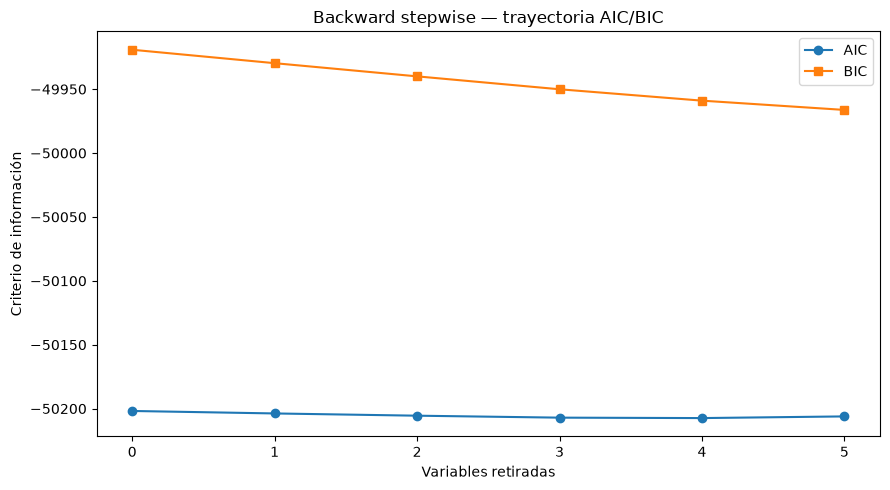

🏃 View run OLS_Log_Backward_Stepwise at: http://127.0.0.1:5000/#/experiments/5/runs/b41a46e003cc4ad39c596e7bd2177688
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5


In [15]:
with mlflow.start_run(run_name='OLS_Log_Backward_Stepwise') as run_stepwise:
    mlflow.set_tag('comparison_group', 'backward_stepwise')
    predictores_stepwise = list(X_train.columns)
    historial_stepwise = []
    paso = 0
    while True:
        X_train_paso = sm.add_constant(X_train[predictores_stepwise], has_constant='add')
        modelo_paso = sm.OLS(y_train_log, X_train_paso).fit()
        historial_stepwise.append({
            'paso': paso,
            'variable_retirada': 'ninguna (modelo completo)' if paso == 0 else variable_retirada,
            'p_value_retirado': np.nan if paso == 0 else p_value_retirado,
            'predictores_activos': len(predictores_stepwise),
            'rss_log': float(np.sum(modelo_paso.resid ** 2)),
            'r2_ajustado_log': float(modelo_paso.rsquared_adj),
            'aic': float(modelo_paso.aic),
            'bic': float(modelo_paso.bic),
        })
        # Cada ajuste se registra antes de decidir el próximo retiro por p-value.
        X_test_paso = sm.add_constant(X_test[predictores_stepwise], has_constant='add')
        duan_paso = float(np.exp(modelo_paso.resid).mean())
        pred_test_paso = np.exp(modelo_paso.predict(X_test_paso)) * duan_paso
        with mlflow.start_run(run_name=f'Stepwise_Paso_{paso:02d}', nested=True):
            mlflow.set_tags({
                'comparison_group': 'backward_stepwise',
                'split_id': 'random_80_20_seed_42',
            })
            mlflow.log_params({
                'tipo_modelo': 'OLS',
                'paso': paso,
                'variable_retirada': 'ninguna' if paso == 0 else variable_retirada,
                'p': len(predictores_stepwise),
                'escala_target': 'log(RUB/m2)',
            })
            mlflow.log_metrics({
                'R2_Train': float(modelo_paso.rsquared),
                'R2_Ajustado_Train': float(modelo_paso.rsquared_adj),
                'aic': float(modelo_paso.aic),
                'bic': float(modelo_paso.bic),
                'rss_log': float(np.sum(modelo_paso.resid ** 2)),
                'duan_factor': duan_paso,
                'test_r2': float(r2_score(y_test, pred_test_paso)),
                'test_mae_RUB_m2': float(mean_absolute_error(y_test, pred_test_paso)),
                'test_rmse_RUB_m2': float(np.sqrt(mean_squared_error(y_test, pred_test_paso))),
            })
            mlflow.statsmodels.log_model(modelo_paso, name='modelo')
            mlflow.log_text(modelo_paso.summary().as_text(),
                            f'modelo/resumen_ols_paso_{paso:02d}.txt')
        candidatos = modelo_paso.pvalues.drop('const')
        variable_mayor_p = candidatos.idxmax()
        p_mayor = float(candidatos.max())
        if p_mayor < 0.05:
            modelo_4_stepwise = modelo_paso
            break
        variable_retirada, p_value_retirado = variable_mayor_p, p_mayor
        predictores_stepwise.remove(variable_retirada)
        paso += 1

    historial_stepwise = pd.DataFrame(historial_stepwise)
    historial_stepwise['delta_aic'] = historial_stepwise['aic'].diff()
    historial_stepwise['delta_bic'] = historial_stepwise['bic'].diff()
    display(historial_stepwise)
    print('Variables retiradas:', historial_stepwise['variable_retirada'].iloc[1:].tolist())
    print('AIC disminuye en todos los pasos:', bool((historial_stepwise['delta_aic'].iloc[1:] < 0).all()))
    print('BIC disminuye en todos los pasos:', bool((historial_stepwise['delta_bic'].iloc[1:] < 0).all()))

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(historial_stepwise['paso'], historial_stepwise['aic'], 'o-', label='AIC')
    ax.plot(historial_stepwise['paso'], historial_stepwise['bic'], 's-', label='BIC')
    ax.set(title='Backward stepwise — trayectoria AIC/BIC', xlabel='Variables retiradas', ylabel='Criterio de información')
    ax.legend()
    fig.tight_layout()
    mlflow.log_figure(fig, 'diagnostico/aic_bic_stepwise.png')
    plt.show()

    X_test_stepwise = sm.add_constant(X_test[predictores_stepwise], has_constant='add')
    assert modelo_4_stepwise.model.exog_names == X_test_stepwise.columns.tolist()
    duan_modelo_4 = float(np.exp(modelo_4_stepwise.resid).mean())
    pred_test_4 = np.exp(modelo_4_stepwise.predict(X_test_stepwise)) * duan_modelo_4
    registrar_modelo('OLS Backward Stepwise', 'log(RUB/m2)', len(predictores_stepwise),
                    modelo_4_stepwise.rsquared_adj, pred_test_4, modelo_4_stepwise,
                    duan=duan_modelo_4)


## 6.3. Ridge con K-Fold

Antes de penalizar los coeficientes estandarizamos los 32 predictores con `StandardScaler` ajustado en train, sin usar el test para calcular medias ni desvíos. Con **K-Fold de K=10** elegimos el valor de lambda para Ridge. El escalado se hace antes de los diez pliegues: es una limitación de este cálculo para elegir lambda, porque cada pliegue comparte las medias y los desvíos obtenidos de todo train.

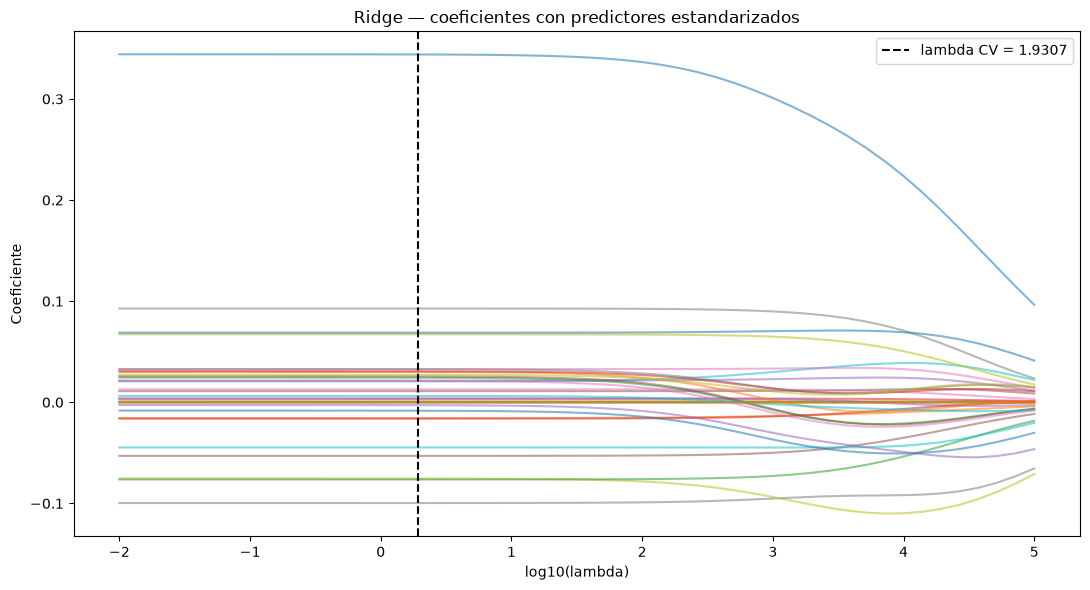

Lambda Ridge CV: 1.9306977288832496 Predictores activos: 32
🏃 View run Ridge_Log_10_Fold_CV at: http://127.0.0.1:5000/#/experiments/5/runs/860842bff4054fa99886e03a92533f9c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5


In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge, RidgeCV, Lasso, LassoCV, lasso_path

escalador_6 = StandardScaler().fit(X_train)
X_train_scaled = escalador_6.transform(X_train)
X_test_scaled = escalador_6.transform(X_test)
assert np.isfinite(X_train_scaled).all() and np.isfinite(X_test_scaled).all()
cv_10 = KFold(n_splits=10, shuffle=True, random_state=42)
alphas_ridge = np.logspace(-2, 5, 50)
with mlflow.start_run(run_name='Ridge_Log_10_Fold_CV') as run_ridge:
    modelo_5_ridge = RidgeCV(alphas=alphas_ridge, cv=cv_10, scoring='neg_mean_squared_error').fit(X_train_scaled, y_train_log)
    duan_modelo_5 = float(np.exp(y_train_log.to_numpy() - modelo_5_ridge.predict(X_train_scaled)).mean())
    pred_test_5 = np.exp(modelo_5_ridge.predict(X_test_scaled)) * duan_modelo_5
    traza_ridge = np.vstack([Ridge(alpha=alpha).fit(X_train_scaled, y_train_log).coef_ for alpha in alphas_ridge])
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.plot(np.log10(alphas_ridge), traza_ridge, alpha=0.55)
    ax.axvline(np.log10(modelo_5_ridge.alpha_), color='black', linestyle='--', label=f'lambda CV = {modelo_5_ridge.alpha_:.5g}')
    ax.set(title='Ridge — coeficientes con predictores estandarizados', xlabel='log10(lambda)', ylabel='Coeficiente')
    ax.legend()
    fig.tight_layout()
    mlflow.log_figure(fig, 'diagnostico/trayectoria_ridge.png')
    plt.show()
    print('Lambda Ridge CV:', modelo_5_ridge.alpha_, 'Predictores activos:', np.count_nonzero(modelo_5_ridge.coef_))
    p_ridge = int(np.count_nonzero(modelo_5_ridge.coef_))
    registrar_modelo('Ridge', 'log(RUB/m2)', p_ridge,
                    r2_ajustado_regularizado(modelo_5_ridge.predict(X_train_scaled), p_ridge),
                    pred_test_5, modelo_5_ridge, duan=duan_modelo_5,
                    alpha=modelo_5_ridge.alpha_, cv=cv_10.n_splits, escalador=escalador_6)


### Lasso y regla de 1 error estándar

Lasso también usa validación cruzada con **K=10**. Comparamos el lambda que da el menor error medio con la **regla 1-SE** vista en clase: elegimos el lambda más grande cuyo error no supere al mínimo más un error estándar. Buscamos así un modelo más simple, siguiendo la Navaja de Ockham, y contamos los coeficientes que Lasso deja exactamente en cero.

🏃 View run Lasso_Log_Lambda_Min at: http://127.0.0.1:5000/#/experiments/5/runs/b9a58791e44b45bcb94f688890cdef6f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5
🏃 View run Lasso_Log_Regla_1_SE at: http://127.0.0.1:5000/#/experiments/5/runs/1ea7a0903bfc42eda2e673772ee821ba
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5
Lambda min: 1e-05; lambda 1-SE: 0.0012638482
Umbral 1-SE de MSE log: 0.01618144
Variables exactamente en cero con lambda 1-SE: ['total_area', 'living_ratio', 'kitchen_ratio', 'antiguedad', 'okrug_YuAO', 'okrug_ZelAO', 'seller_type_owner']


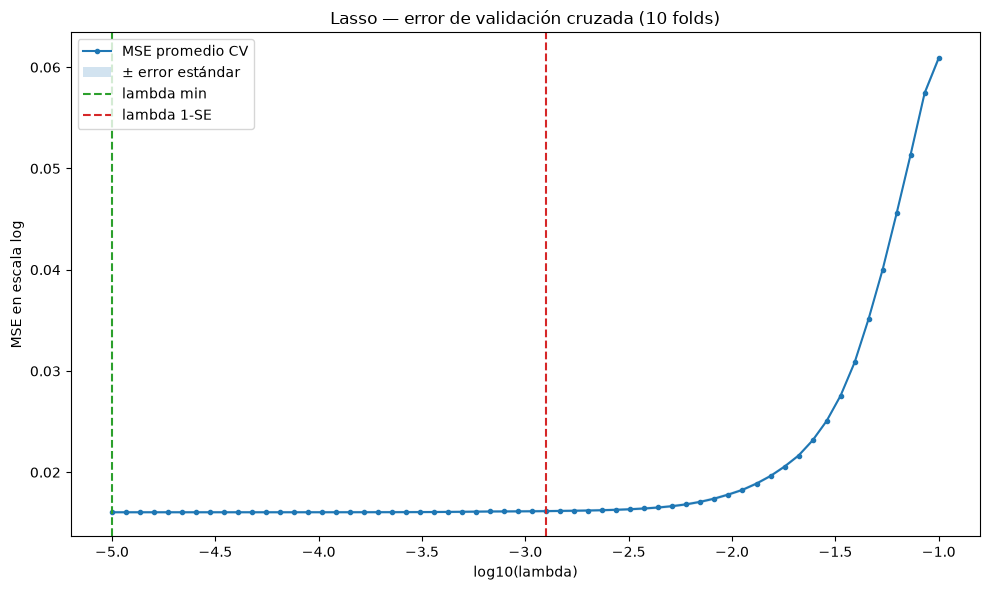

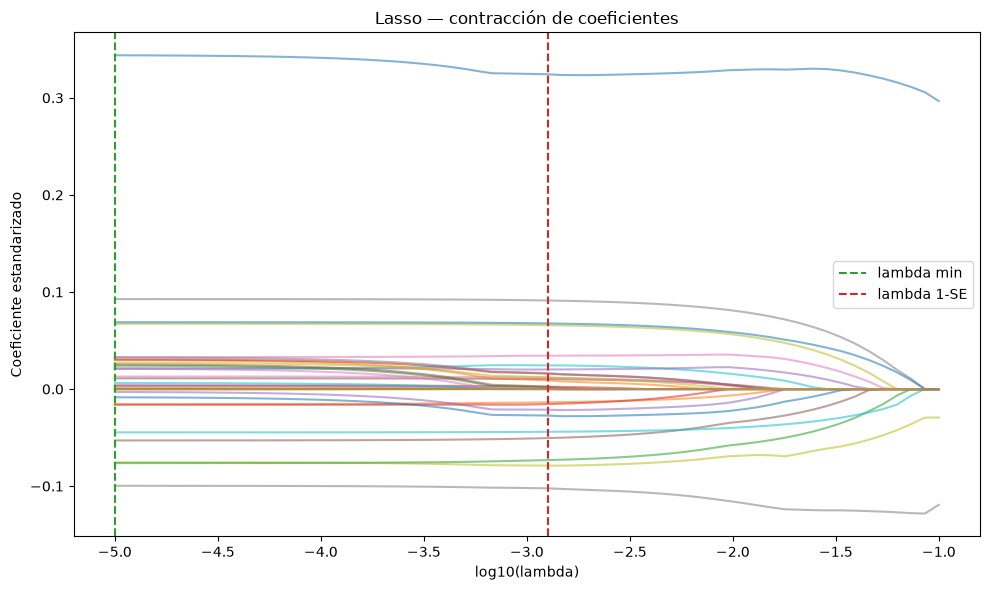

In [17]:
alphas_lasso = np.logspace(-5, -1, 60)
with mlflow.start_run(run_name='Lasso_Log_Lambda_Min') as run_lasso_min:
    modelo_6_lasso_min = LassoCV(alphas=alphas_lasso, cv=cv_10, max_iter=20000, tol=1e-4, n_jobs=2).fit(X_train_scaled, y_train_log)
    mse_cv = modelo_6_lasso_min.mse_path_
    assert mse_cv.shape == (len(alphas_lasso), 10)
    media_mse_cv = mse_cv.mean(axis=1)
    error_estandar_cv = mse_cv.std(axis=1, ddof=1) / np.sqrt(cv_10.n_splits)
    indice_min_cv = int(np.argmin(media_mse_cv))
    umbral_un_se = media_mse_cv[indice_min_cv] + error_estandar_cv[indice_min_cv]
    indices_elegibles = np.flatnonzero(media_mse_cv <= umbral_un_se)
    alpha_min = float(modelo_6_lasso_min.alpha_)
    alpha_un_se = float(modelo_6_lasso_min.alphas_[indices_elegibles].max())
    assert alpha_un_se >= alpha_min
    duan_modelo_6 = float(np.exp(y_train_log.to_numpy() - modelo_6_lasso_min.predict(X_train_scaled)).mean())
    pred_test_6 = np.exp(modelo_6_lasso_min.predict(X_test_scaled)) * duan_modelo_6
    p_lasso_min = int(np.count_nonzero(modelo_6_lasso_min.coef_))
    registrar_modelo('Lasso', 'log(RUB/m2)', p_lasso_min,
                    r2_ajustado_regularizado(modelo_6_lasso_min.predict(X_train_scaled), p_lasso_min),
                    pred_test_6, modelo_6_lasso_min, duan=duan_modelo_6,
                    alpha=alpha_min, cv=cv_10.n_splits, escalador=escalador_6)

with mlflow.start_run(run_name='Lasso_Log_Regla_1_SE') as run_lasso_1se:
    modelo_7_lasso_un_se = Lasso(alpha=alpha_un_se, max_iter=20000, tol=1e-4).fit(X_train_scaled, y_train_log)
    duan_modelo_7 = float(np.exp(y_train_log.to_numpy() - modelo_7_lasso_un_se.predict(X_train_scaled)).mean())
    pred_test_7 = np.exp(modelo_7_lasso_un_se.predict(X_test_scaled)) * duan_modelo_7
    p_lasso_1se = int(np.count_nonzero(modelo_7_lasso_un_se.coef_))
    registrar_modelo('Lasso', 'log(RUB/m2)', p_lasso_1se,
                    r2_ajustado_regularizado(modelo_7_lasso_un_se.predict(X_train_scaled), p_lasso_1se),
                    pred_test_7, modelo_7_lasso_un_se, duan=duan_modelo_7,
                    alpha=alpha_un_se, cv=cv_10.n_splits, escalador=escalador_6)
coef_lasso_un_se = pd.Series(modelo_7_lasso_un_se.coef_, index=X_train.columns)
predictores_en_cero_un_se = coef_lasso_un_se.index[coef_lasso_un_se.eq(0.0)].tolist()
print(f'Lambda min: {alpha_min:.8g}; lambda 1-SE: {alpha_un_se:.8g}')
print(f'Umbral 1-SE de MSE log: {umbral_un_se:.8f}')
print('Variables exactamente en cero con lambda 1-SE:', predictores_en_cero_un_se)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(np.log10(modelo_6_lasso_min.alphas_), media_mse_cv, 'o-', markersize=3, label='MSE promedio CV')
ax.fill_between(np.log10(modelo_6_lasso_min.alphas_), media_mse_cv - error_estandar_cv, media_mse_cv + error_estandar_cv, alpha=0.2, label='± error estándar')
ax.axvline(np.log10(alpha_min), color='tab:green', linestyle='--', label='lambda min')
ax.axvline(np.log10(alpha_un_se), color='tab:red', linestyle='--', label='lambda 1-SE')
ax.set(title='Lasso — error de validación cruzada (10 folds)', xlabel='log10(lambda)', ylabel='MSE en escala log')
ax.legend()
fig.tight_layout()
fig_lasso_cv = fig
plt.show()

alphas_traza, coeficientes_traza, _ = lasso_path(
    X_train_scaled, y_train_log.to_numpy() - y_train_log.mean(),
    alphas=modelo_6_lasso_min.alphas_, max_iter=20000, tol=1e-4,
)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(np.log10(alphas_traza), coeficientes_traza.T, alpha=0.55)
ax.axvline(np.log10(alpha_min), color='tab:green', linestyle='--', label='lambda min')
ax.axvline(np.log10(alpha_un_se), color='tab:red', linestyle='--', label='lambda 1-SE')
ax.set(title='Lasso — contracción de coeficientes', xlabel='log10(lambda)', ylabel='Coeficiente estandarizado')
ax.legend()
fig.tight_layout()
fig_lasso_coeficientes = fig
plt.show()

## 6.4. Comparación de los siete modelos

En la tabla `p` indica la cantidad de predictores con coeficiente activo, sin contar el intercepto. Comparamos R², MAE y RMSE sobre las mismas 9.698 propiedades de test y en RUB/m².

In [18]:
modelos_finales = [
    ('1. OLS Lineal', X_train.shape[1], pred_test_1),
    ('2. OLS Log Completo', X_train.shape[1], pred_test_2),
    ('3. OLS Log sin mensuales', X_train_sin_mensuales.shape[1] - 1, pred_test_3),
    ('4. OLS Log Backward Stepwise', len(predictores_stepwise), pred_test_4),
    ('5. Ridge Log 10-Fold CV', int(np.count_nonzero(modelo_5_ridge.coef_)), pred_test_5),
    ('6. Lasso Log lambda_min', int(np.count_nonzero(modelo_6_lasso_min.coef_)), pred_test_6),
    ('7. Lasso Log Regla 1-SE', int(np.count_nonzero(modelo_7_lasso_un_se.coef_)), pred_test_7),
]
comparacion_final_modelos = pd.DataFrame([
    {
        'modelo': nombre, 'p': int(activos),
        'r2_test_RUB_m2': float(r2_score(y_test, prediccion)),
        'mae_test_RUB_m2': float(mean_absolute_error(y_test, prediccion)),
        'rmse_test_RUB_m2': float(np.sqrt(mean_squared_error(y_test, prediccion))),
    }
    for nombre, activos, prediccion in modelos_finales
])
assert len(comparacion_final_modelos) == 7
assert np.isfinite(comparacion_final_modelos.select_dtypes(include='number').to_numpy()).all()
assert np.allclose(comparacion_final_modelos.loc[:2, 'rmse_test_RUB_m2'], comparacion_ols['rmse_test_RUB_m2'])
RUTA_COMPARACION_FINAL = Path('comparacion_final_modelos_lineales.csv')
comparacion_final_modelos.to_csv(RUTA_COMPARACION_FINAL, index=False)
display(comparacion_final_modelos)
print(f'Tabla guardada en: {RUTA_COMPARACION_FINAL.resolve()}')

,modelo,p,r2_test_RUB_m2,mae_test_RUB_m2,rmse_test_RUB_m2
0,1. OLS Lineal,32,0.913225,23224.612975,33601.673921
1,2. OLS Log Completo,32,0.914842,20493.906012,33287.148716
2,3. OLS Log sin mensuales,30,0.873093,27658.675172,40635.701565
3,4. OLS Log Backward Stepwise,27,0.914732,20494.388134,33308.675673
4,5. Ridge Log 10-Fold CV,32,0.914881,20492.540280,33279.511750
5,6. Lasso Log lambda_min,32,0.914885,20492.491443,33278.881813
6,7. Lasso Log Regla 1-SE,25,0.916851,20475.887361,32892.285085


Tabla guardada en: C:\Users\Rodrigo\Documents\Facultad\Analisis de datos\Parcial\2round\comparacion_final_modelos_lineales.csv


## 6.5. Artefactos de las corridas

Para conservar el análisis junto con las métricas, guardamos en MLflow el dataset de modelado, las tablas y las figuras que construimos en las secciones anteriores. Los runs de OLS incluyen el resumen de coeficientes y los diagnósticos; Stepwise, Ridge y Lasso conservan sus trayectorias y resultados. El modelo entrenado también aparece en el enlace **Models** de cada run, mientras que las figuras y tablas quedan en su pestaña **Artifacts**. Usamos los mismos objetos ya calculados: este registro no modifica la comparación de modelos.

In [ ]:
# Reopen the same runs so tables and figures computed in later cells stay with their model.
with mlflow.start_run(run_id=run_ols_lineal.info.run_id):
    mlflow.log_text(modelo_1_lineal.summary().as_text(), 'modelo/resumen_ols_lineal.txt')
    mlflow.log_table(comparacion_ols, 'diagnostico/comparacion_tres_ols.json')

with mlflow.start_run(run_id=run_ols_log.info.run_id):
    mlflow.log_artifact(str(RUTA_OHE_OLS), artifact_path='dataset')
    mlflow.log_text(modelo_2_log.summary().as_text(), 'modelo/resumen_ols_log.txt')
    for tabla, nombre in [
        (eda[columnas_eda].describe().T.reset_index().rename(columns={'index': 'variable'}), 'resumen_numericas'),
        (correlaciones_pearson.reset_index().rename(columns={'index': 'variable'}), 'correlacion_pearson'),
        (vif_numericas, 'vif_numericas'),
        (resumen_simetria, 'simetria_precio'),
        (segmentos, 'precios_por_zona'),
        (resumen_gradiente.assign(quintil_distancia=resumen_gradiente['quintil_distancia'].astype(str)), 'precio_por_distancia'),
        (comparacion_ols, 'comparacion_tres_ols'),
        (inferencia_modelo_2, 'coeficientes_ols'),
        (diagnostico_residuos_2, 'estadisticos_residuos'),
        (comparacion_final_modelos, 'comparacion_siete_modelos'),
    ]:
        mlflow.log_table(tabla, f'diagnostico/{nombre}.json')
    for figura, nombre in [
        (fig_correlaciones, 'correlacion_pearson'),
        (fig_categorias, 'precio_por_categorias'),
        (fig_simetria, 'simetria_precio'),
        (fig_zonas, 'precios_por_zona'),
        (fig_impactos_dummy, 'impactos_dummy'),
        (fig_residuos_ols, 'residuos_vs_ajustados'),
        (fig_diagnostico_residuos, 'histograma_qq_residuos_scale_location'),
    ]:
        mlflow.log_figure(figura, f'diagnostico/{nombre}.png')

with mlflow.start_run(run_id=run_ols_sin_mensuales.info.run_id):
    mlflow.log_text(modelo_3_log_sin_mensuales.summary().as_text(), 'modelo/resumen_ols_sin_mensuales.txt')
    mlflow.log_table(comparacion_ols, 'diagnostico/comparacion_tres_ols.json')

for run_id in runs_superficies.values():
    with mlflow.start_run(run_id=run_id):
        mlflow.log_table(comparacion_superficies, 'diagnostico/comparacion_superficies.json')

with mlflow.start_run(run_id=run_stepwise.info.run_id):
    mlflow.log_text(modelo_4_stepwise.summary().as_text(), 'modelo/resumen_ols_stepwise.txt')
    mlflow.log_table(historial_stepwise, 'diagnostico/historial_stepwise.json')
    mlflow.log_table(comparacion_final_modelos, 'diagnostico/comparacion_siete_modelos.json')

with mlflow.start_run(run_id=run_ridge.info.run_id):
    mlflow.log_table(pd.DataFrame({
        'variable': X_train.columns, 'coeficiente_estandarizado': modelo_5_ridge.coef_,
    }), 'modelo/coeficientes_ridge.json')

for run_id, modelo in [
    (run_lasso_min.info.run_id, modelo_6_lasso_min),
    (run_lasso_1se.info.run_id, modelo_7_lasso_un_se),
]:
    with mlflow.start_run(run_id=run_id):
        mlflow.log_table(pd.DataFrame({
            'variable': X_train.columns, 'coeficiente_estandarizado': modelo.coef_,
        }), 'modelo/coeficientes_lasso.json')
        mlflow.log_figure(fig_lasso_cv, 'diagnostico/error_cv_lasso.png')
        mlflow.log_figure(fig_lasso_coeficientes, 'diagnostico/trayectoria_lasso.png')
        mlflow.log_table(comparacion_final_modelos, 'diagnostico/comparacion_siete_modelos.json')


### Lectura de los diagnósticos y modelos

- Los residuos de train del Modelo 2 tienen media cercana a **0**, Durbin–Watson **1,995** (dentro del rango orientativo **1,5 a 2,5** y muy próximo a 2), `Skew` **−0,12** (dentro de [−0,5; 0,5]) y curtosis de Pearson **3,35**. En el histograma y el QQ-Plot observamos la forma y las colas; residuos vs. ajustados y Scale-Location permiten revisar la dispersión. Omnibus y Jarque–Bera rechazan normalidad exacta. Como las filas se mezclaron, Durbin–Watson no prueba independencia temporal.
- En Backward Stepwise retiramos, una por una, `total_area`, `kitchen_ratio`, `seller_type_owner`, `okrug_TAO` y `living_ratio`. Quedaron **27 variables con p < 0,05** en el último ajuste. **BIC bajó en los cinco pasos; AIC bajó en los primeros cuatro y subió 1,307 en el quinto.** Registramos ambos criterios tal como dieron, sin forzar que coincidan.
- Ridge seleccionó **lambda = 1,9307** con 10 pliegues. En Lasso, el lambda del menor error fue **0,00001**; con la regla 1-SE, **0,00126385**. Esta última llevó **7 variables a cero**, quedó con **25 predictores** y obtuvo el menor RMSE de test (**32.892,29 RUB/m²**).

# Sección 7 — Conclusiones

Partimos de **50.000** avisos de `secondary_market.csv` y sumamos precios distritales por mes desde `district_prices_monthly.csv` y características del metro desde `metro_stations.csv`. Los dos cruces conservaron las filas. Después descartamos **247** inconsistencias de superficie y **1.266** avisos cuyo edificio figuraba construido después de la publicación. Quedaron **48.487** propiedades; también completamos **622** datos faltantes de variación mensual con cero.

Pasamos `living_area` y `kitchen_area` a `living_ratio` y `kitchen_ratio`, además de usar `floor_ratio` y `antiguedad`. En las variables numéricas seleccionadas el VIF de `total_area` bajó de **14,21 a 1,33**, y todos los VIF quedaron debajo de 10. El precio original mostró *Positive Skew* (**+1,69**); con `log(price_per_sqm)` pasó a **−0,20** y su curtosis de Pearson se acercó a 3 (**3,22**). Los precios de algunas propiedades renovadas fuera de CAO se cruzan con los del tramo bajo/medio de CAO, aunque las zonas tienen medianas diferentes. Por eso probamos un primer modelo conjunto que incluye `to_center_km` y `okrug`.

En el test común de **9.698** observaciones, **Lasso log con regla 1-SE** logró el menor RMSE (**32.892,29 RUB/m²**) con **25 predictores**, **R² = 0,9169** y **MAE = 20.475,89 RUB/m²**. El **OLS log Backward Stepwise** conservó **27 predictores** y logró **RMSE = 33.308,68 RUB/m²**; frente al OLS log completo, es una alternativa más simple con error parecido. La tabla final muestra los siete modelos y permite revisar el equilibrio entre simplicidad y predicción.

El test fue aleatorio. Antes de usar estos resultados para predecir avisos de meses futuros, tendríamos que evaluarlos con una separación por fechas.